# w14a — Logistic Regression in Python
**ENGR 1451/2451 · Exploratory Data Science**

Use `glm()`, `.predict()`, `pd.crosstab()`, and `roc_curve()` to fit and evaluate a logistic classifier. We use 45 Donner Party records; **died = 1** is the positive class throughout. 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.metrics import roc_curve, roc_auc_score

## 1. Read the data

Create two indicators: `died` (1 = died, 0 = survived) and `female` (1 = female, 0 = male). What do the counts show?

In [2]:
donner = pd.read_csv("data/donner.csv")
donner = donner.rename(columns={"Age": "age", "Sex": "sex", "Status": "status"})
donner["died"] = (donner["status"] == "Died").astype(int)
donner["female"] = (donner["sex"] == "Female").astype(int)
display(donner.head())
pd.crosstab(donner["sex"], donner["died"])

,age,sex,status,died,female
0,23,Male,Died,1,0
1,40,Female,Survived,0,1
2,40,Male,Survived,0,0
3,30,Male,Died,1,0
4,28,Male,Died,1,0


died,0,1
sex,,
Female,10,5
Male,10,20


## 2. Fit logistic regression

For $p=P(\mathrm{died}=1)$, logistic regression models **log-odds**:

$$\log\left(\frac{p}{1-p}\right)=\beta_0+\beta_1\,\mathrm{age}+\beta_2\,\mathrm{female}.$$

A binomial GLM estimates the coefficients. `np.exp()` converts each coefficient into an **odds multiplier** (not a probability change). `.summary()` gives P-values; `.conf_int()` gives coefficient intervals.

In [3]:
model = smf.glm("died ~ age + female", data=donner,
                family=sm.families.Binomial()).fit()
print(model.summary().tables[1])
print("Odds multipliers:")
display(np.exp(model.params).round(3))
print("95% confidence intervals for odds multipliers:")
display(np.exp(model.conf_int()).round(3))

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.6331      1.110     -1.471      0.141      -3.809       0.543
age            0.0782      0.037      2.097      0.036       0.005       0.151
female        -1.5973      0.756     -2.114      0.034      -3.078      -0.117
Odds multipliers:


Intercept    0.195
age          1.081
female       0.202
dtype: float64

95% confidence intervals for odds multipliers:


,0,1
Intercept,0.022,1.721
age,1.005,1.163
female,0.046,0.890


## 3. Fitted probabilities and observed outcomes

`.predict()` gives probabilities, not 0/1 predictions. The curves below hold sex fixed and vary age; dots show the actual binary observations (jittered only to reveal overlaps).

**Plot key throughout:** Blue = male; orange = female; circle (○) = survived; X (×) = died.

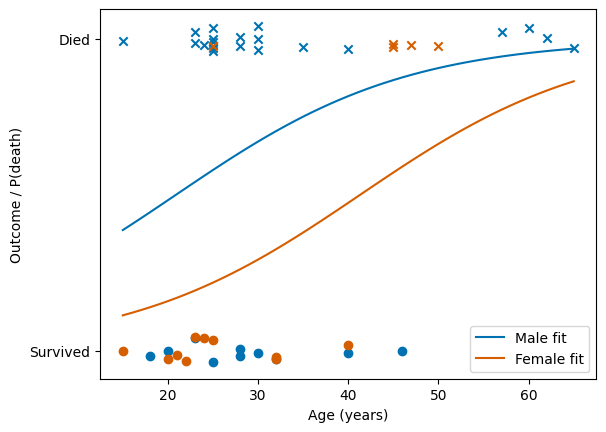

In [4]:
ages = np.arange(15, 66)
jitter = np.random.default_rng(1451).uniform(-0.045, 0.045, len(donner))
colors = {"Male": "#0072B2", "Female": "#D55E00"}
markers = {0: "o", 1: "x"}  # Survived = circle; died = X

def plot_people(x):
    for sex, color in colors.items():
        for outcome, marker in markers.items():
            group = donner[(donner["sex"] == sex) & (donner["died"] == outcome)]
            plt.scatter(group[x], group["died"] + jitter[group.index],
                        color=color, marker=marker)

plot_people("age")
for female, sex in [(0, "Male"), (1, "Female")]:
    new = pd.DataFrame({"age": ages, "female": female})
    plt.plot(ages, model.predict(new), color=colors[sex], label=f"{sex} fit")
plt.xlabel("Age (years)")
plt.ylabel("Outcome / P(death)")
plt.yticks([0, 1], ["Survived", "Died"])
plt.legend()
plt.show()

In [5]:
people = pd.DataFrame({"age": [25, 25, 50, 50], "female": [0, 1, 0, 1]})
people["p_death"] = model.predict(people)
display(people.round(3))

,age,female,p_death
0,25,0,0.580
1,25,1,0.218
2,50,0,0.907
3,50,1,0.664


## 4. Classification thresholds

Predict **death** when $\hat p\geq t$. Lowering $t$ detects more deaths but usually creates more false alarms.

**Sensitivity** = TP/(TP+FN); **specificity** = TN/(TN+FP). Compare the three thresholds from the slides (0.25, 0.50, 0.75).

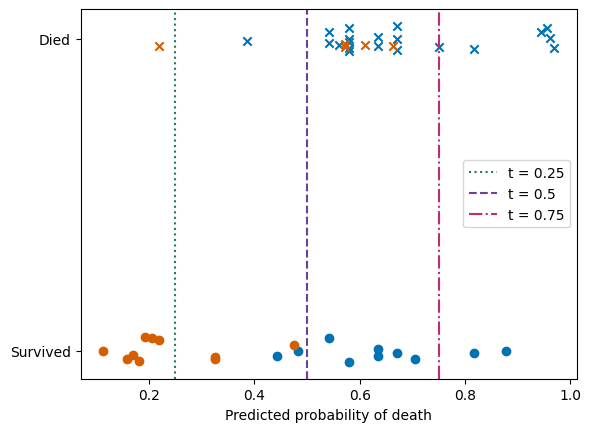

In [6]:
donner["p_death"] = model.predict(donner)
plot_people("p_death")
for t, color, style in [(0.25, "#1B7E57", ":"),
                        (0.50, "#6D3F98", "--"),
                        (0.75, "#C12C70", "-.")]:
    plt.axvline(t, color=color, linestyle=style, label=f"t = {t}")
plt.xlabel("Predicted probability of death")
plt.yticks([0, 1], ["Survived", "Died"])
plt.legend()
plt.show()

In [7]:
results = []
for t in [0.75, 0.50, 0.25]:
    predicted = (donner["p_death"] >= t).astype(int)
    cm = pd.crosstab(donner["died"], predicted).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
    tn, fp, fn, tp = cm.to_numpy().ravel()
    results.append({"t": t, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
                    "Sensitivity": tp/(tp+fn), "Specificity": tn/(tn+fp),
                    "Accuracy": (tp+tn)/len(donner), "Cost": fp+10*fn})
display(pd.DataFrame(results).round(3))

,t,TP,FP,FN,TN,Sensitivity,Specificity,Accuracy,Cost
0,0.75,6,2,19,18,0.24,0.90,0.533,192
1,0.50,23,8,2,12,0.92,0.60,0.778,28
2,0.25,24,13,1,7,0.96,0.35,0.689,23


The **cost** column uses the hypothetical slide penalty $FP+10\,FN$. The counts are from these 45 people, but the relative error cost is an assumption. Which threshold has the best accuracy? Which has the lowest penalty?

## 5. ROC and AUC

`roc_curve()` computes sensitivity (TPR) and false-positive rate ($1-$specificity) across thresholds. `roc_auc_score()` summarizes how well predicted probabilities rank deaths above survivors.

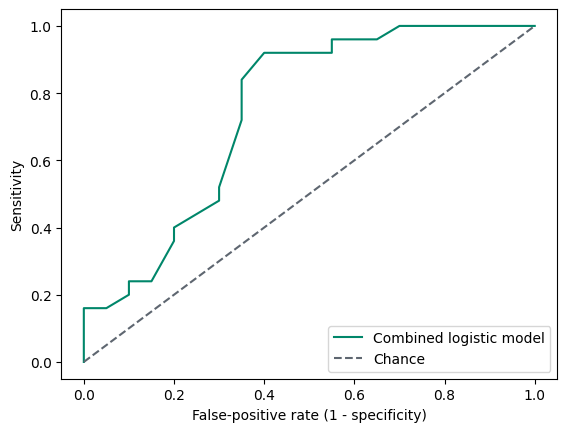

In-sample AUC: 0.746


In [8]:
fpr, tpr, thresholds = roc_curve(donner["died"], donner["p_death"])
plt.plot(fpr, tpr, color="#00866A", label="Combined logistic model")
plt.plot([0, 1], [0, 1], "--", color="#5E6670", label="Chance")
plt.xlabel("False-positive rate (1 - specificity)")
plt.ylabel("Sensitivity")
plt.legend()
plt.show()
print("In-sample AUC:", round(roc_auc_score(donner["died"], donner["p_death"]), 3))

## Try it yourself

1. Use `.loc` to list females younger than 35 (`age` and `status` only).
2. Use `model.predict()` for a 35-year-old male and female. Compare the two death probabilities.
3. Use `np.exp(10 * model.params["age"])` to find the odds multiplier for 10 additional years. Is this a probability multiplier?

**Core commands:** `pd.read_csv`, `.rename`, `.astype`, `smf.glm(...).fit()`, `.summary()`, `np.exp`, `.conf_int()`, `.predict()`, `pd.crosstab`, `roc_curve`, `roc_auc_score`.